<a href="https://colab.research.google.com/github/evangelin-golda/Language-identifier/blob/main/DL_TEST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import glob
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully")

Libraries imported successfully


In [ ]:
from google.colab import files

uploaded = files.upload()

csv_files = [
    name for name in uploaded.keys()
    if name.lower().endswith(".csv")
]

if not csv_files:
    raise ValueError("Please upload the dataset CSV file.")

file_path = csv_files[0]
print("Dataset file:", file_path)

Saving dataset.csv to dataset.csv
Dataset file: dataset.csv


In [ ]:
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nDataset information:")
df.info()

Dataset shape: (22000, 2)

Column names:
['Text', 'language']

First five rows:


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 22000 entries, 0 to 21999
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Text      22000 non-null  object
 1   language  22000 non-null  object
dtypes: object(2)
memory usage: 343.9+ KB


In [ ]:
# Find text and language columns
text_col = next(
    (c for c in df.columns if c.lower().strip() in
     ["text", "text_snippet", "sentence", "content"]),
    None
)

label_col = next(
    (c for c in df.columns if c.lower().strip() in
     ["language", "lang", "label", "target"]),
    None
)

if text_col is None or label_col is None:
    raise ValueError(
        f"Could not identify columns. Available columns: {df.columns.tolist()}"
    )

# Keep only the required columns
df = df[[text_col, label_col]].copy()
df.columns = ["text", "language"]

# Remove missing and empty values
df = df.dropna(subset=["text", "language"])
df["text"] = df["text"].astype(str).str.strip()
df["language"] = df["language"].astype(str).str.strip()

df = df[
    (df["text"] != "") &
    (df["language"] != "")
]

# Remove duplicate text-label pairs
df = df.drop_duplicates(subset=["text", "language"])

df = df.reset_index(drop=True)

print("Shape after cleaning:", df.shape)
print("\nLanguage distribution:")
print(df["language"].value_counts())

Shape after cleaning: (21858, 2)

Language distribution:
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


In [ ]:
def preprocess_text(text):
    text = str(text).lower()
    text = re.sub(r"[^\w\s]", " ", text, flags=re.UNICODE)
    text = re.sub(r"_+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["text"] = df["text"].apply(preprocess_text)

# Remove text that becomes empty after preprocessing
df = df[df["text"] != ""].reset_index(drop=True)

print(df.head())
print("\nPreprocessing completed.")

                                                text  language
0  klement gottwaldi surnukeha palsameeriti ning ...  Estonian
1  sebes joseph pereira thomas på eng the jesuits...   Swedish
2  ถนนเจร ญกร ง อ กษรโรม น thanon charoen krung เ...      Thai
3  வ ச கப பட ட னம தம ழ ச சங கத த இந த ப பத த ர க ...     Tamil
4  de spons behoort tot het geslacht haliclona en...     Dutch

Preprocessing completed.


In [ ]:
SAMPLES_PER_LANGUAGE = 600

df = (
    df.groupby("language", group_keys=False)
      .sample(n=SAMPLES_PER_LANGUAGE, random_state=42)
      .reset_index(drop=True)
)

print("Dataset shape:", df.shape)
print("Total samples:", len(df))
print("Number of languages:", df["language"].nunique())
print("\nSamples per language:")
print(df["language"].value_counts())

Dataset shape: (13200, 2)
Total samples: 13200
Number of languages: 22

Samples per language:
language
Arabic        600
Chinese       600
Dutch         600
English       600
Estonian      600
French        600
Hindi         600
Indonesian    600
Japanese      600
Korean        600
Latin         600
Persian       600
Portugese     600
Pushto        600
Romanian      600
Russian       600
Spanish       600
Swedish       600
Tamil         600
Thai          600
Turkish       600
Urdu          600
Name: count, dtype: int64


In [ ]:
label_encoder = LabelEncoder()

df["label"] = label_encoder.fit_transform(df["language"])

X = df["text"].values
y = df["label"].values

num_classes = len(label_encoder.classes_)

print("Number of classes:", num_classes)
print("\nLanguage mapping:")

for i, language in enumerate(label_encoder.classes_):
    print(language, ":", i)

Number of classes: 22

Language mapping:
Arabic : 0
Chinese : 1
Dutch : 2
English : 3
Estonian : 4
French : 5
Hindi : 6
Indonesian : 7
Japanese : 8
Korean : 9
Latin : 10
Persian : 11
Portugese : 12
Pushto : 13
Romanian : 14
Russian : 15
Spanish : 16
Swedish : 17
Tamil : 18
Thai : 19
Turkish : 20
Urdu : 21


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 10560
Testing samples: 2640


In [ ]:
MAX_WORDS = 20000
MAX_LEN = 100

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=MAX_LEN,
    padding="post",
    truncating="post"
)

vocab_size = min(MAX_WORDS, len(tokenizer.word_index) + 1)

print("Vocabulary size:", vocab_size)
print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)

Vocabulary size: 20000
Training shape: (10560, 100)
Testing shape: (2640, 100)


In [ ]:
model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
history = model.fit(
    X_train_pad,
    y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    verbose=1
)

Epoch 1/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 8s 12ms/step - accuracy: 0.3128 - loss: 2.2191 - val_accuracy: 0.5814 - val_loss: 1.3049
Epoch 2/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.5984 - loss: 1.2553 - val_accuracy: 0.8097 - val_loss: 0.8070
Epoch 3/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.8176 - loss: 0.6803 - val_accuracy: 0.9072 - val_loss: 0.4659
Epoch 4/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.7274 - loss: 1.1016 - val_accuracy: 0.8665 - val_loss: 0.5978
Epoch 5/5
149/149 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.8743 - loss: 0.5332 - val_accuracy: 0.9081 - val_loss: 0.3917


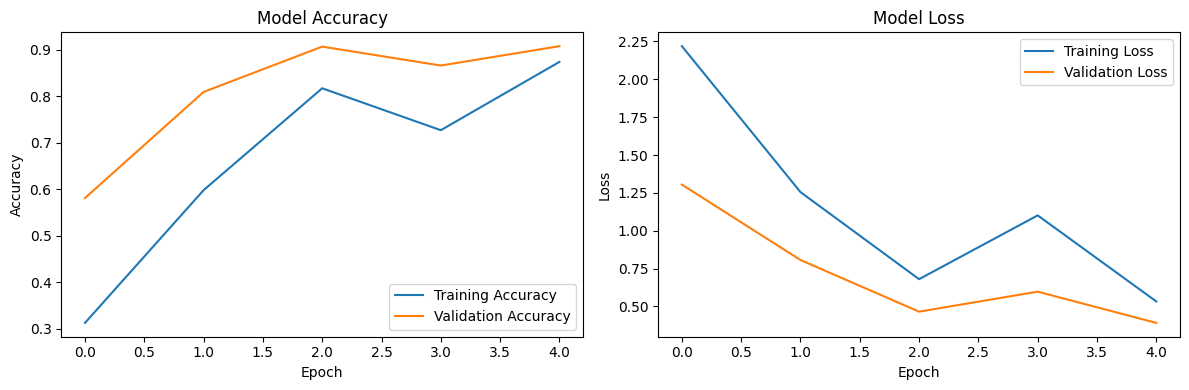

In [ ]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
y_prob = model.predict(X_test_pad, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(
    y_test, y_pred, average="macro", zero_division=0
))
print("Recall   :", recall_score(
    y_test, y_pred, average="macro", zero_division=0
))
print("F1-score :", f1_score(
    y_test, y_pred, average="macro", zero_division=0
))

Accuracy : 0.9045454545454545
Precision: 0.9125474030624663
Recall   : 0.9045454545454544
F1-score : 0.906031293333447


In [ ]:
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

              precision    recall  f1-score   support

      Arabic       0.99      0.91      0.95       120
     Chinese       0.53      0.61      0.57       120
       Dutch       0.97      0.96      0.96       120
     English       0.82      0.98      0.89       120
    Estonian       0.95      0.93      0.94       120
      French       0.83      0.98      0.90       120
       Hindi       1.00      1.00      1.00       120
  Indonesian       0.99      0.97      0.98       120
    Japanese       0.61      0.63      0.62       120
      Korean       0.78      0.92      0.84       120
       Latin       0.79      0.79      0.79       120
     Persian       0.96      0.99      0.98       120
   Portugese       0.99      0.95      0.97       120
      Pushto       1.00      0.91      0.95       120
    Romanian       0.97      0.93      0.94       120
     Russian       0.97      0.95      0.96       120
     Spanish       1.00      0.90      0.95       120
     Swedish       1.00    

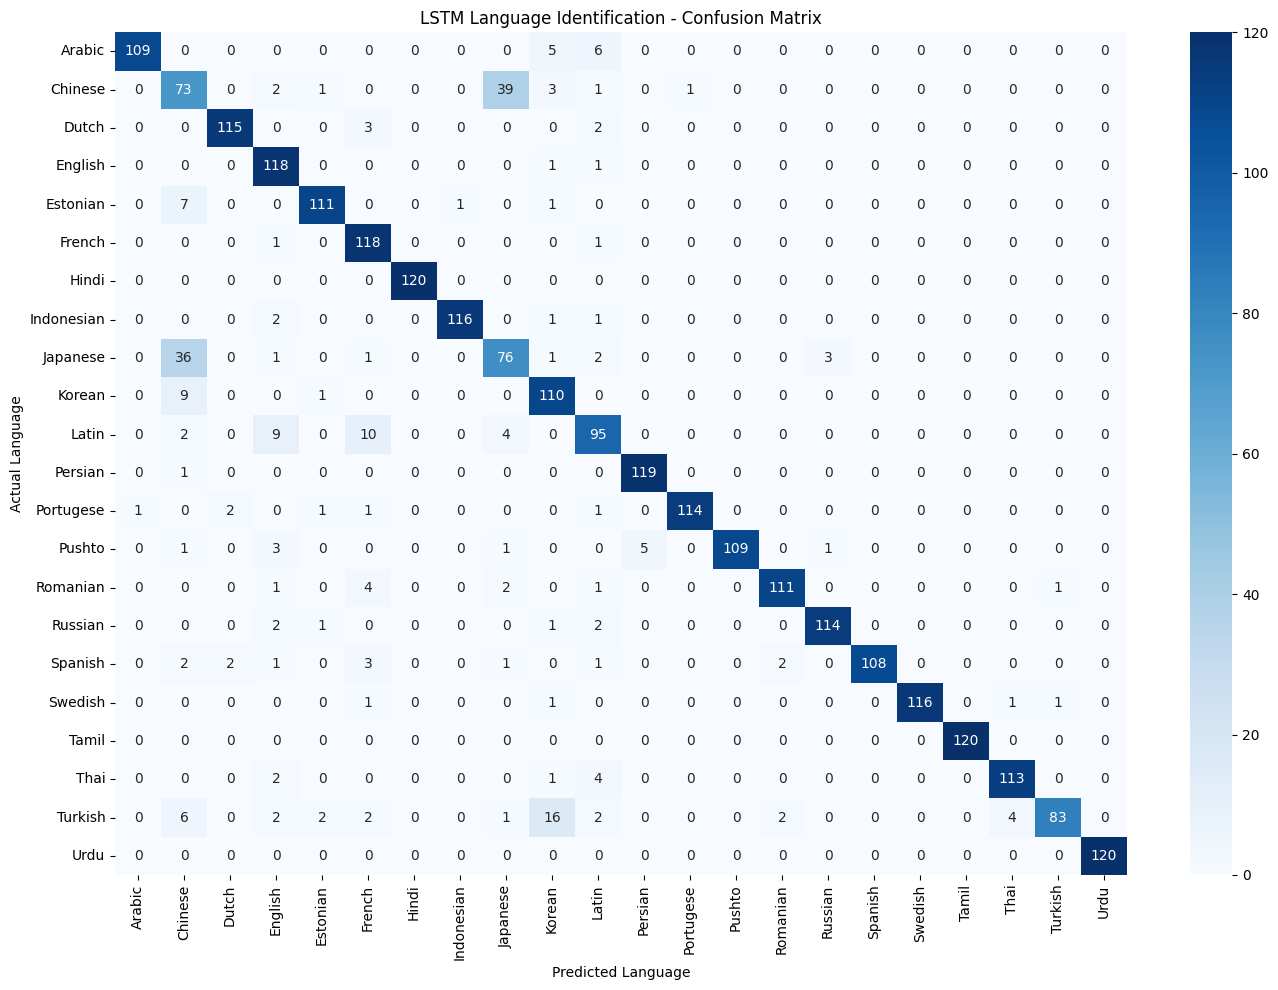

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(num_classes)
)

plt.figure(figsize=(14, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("LSTM Language Identification - Confusion Matrix")
plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [ ]:
unseen_texts = [
    "Hello, how are you today?",
    "Bonjour, comment allez-vous aujourd'hui?",
    "Hola, ¿cómo estás hoy?",
    "Guten Tag, wie geht es Ihnen heute?",
    "வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?"
]

def predict_language(texts):
    cleaned = [preprocess_text(t) for t in texts]
    sequences = tokenizer.texts_to_sequences(cleaned)

    padded = pad_sequences(
        sequences,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probabilities = model.predict(padded, verbose=0)
    predicted_ids = np.argmax(probabilities, axis=1)

    results = []

    for text, pred_id, probs in zip(texts, predicted_ids, probabilities):
        results.append({
            "Input Text": text,
            "Predicted Language":
                label_encoder.inverse_transform([pred_id])[0],
            "Confidence (%)": round(float(probs[pred_id]) * 100, 2)
        })

    return pd.DataFrame(results)

display(predict_language(unseen_texts))

,Input Text,Predicted Language,Confidence (%)
0,"Hello, how are you today?",English,11.18
1,"Bonjour, comment allez-vous aujourd'hui?",Japanese,44.66
2,"Hola, ¿cómo estás hoy?",Japanese,17.43
3,"Guten Tag, wie geht es Ihnen heute?",Japanese,14.27
4,"வணக்கம், நீங்கள் எப்படி இருக்கிறீர்கள்?",Tamil,96.54


In [ ]:
def predict_my_sentence():
    text = input("Enter a sentence: ")

    # Preprocess the input
    cleaned_text = preprocess_text(text)

    # Convert text into numerical sequences
    sequence = tokenizer.texts_to_sequences([cleaned_text])

    # Pad the sequence
    padded_sequence = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    # Predict the language
    probabilities = model.predict(padded_sequence, verbose=0)

    predicted_id = np.argmax(probabilities[0])
    predicted_language = label_encoder.inverse_transform(
        [predicted_id]
    )[0]

    confidence = probabilities[0][predicted_id] * 100

    print("\n--- Language Prediction ---")
    print("Input sentence:", text)
    print("Predicted language:", predicted_language)
    print(f"Confidence: {confidence:.2f}%")

predict_my_sentence()

Enter a sentence: èƒ¡èµ›å°¼æœ¬äººå’Œå°è¯´çš„ä¸»äººå…¬é˜¿ç±³å°”ä¸€æ ·ï¼Œéƒ½æ˜¯å‡ºç”Ÿåœ¨é˜¿å¯Œæ±—é¦–éƒ½å–€å¸ƒå°”ï¼Œå°‘å¹´æ—¶ä»£ä¾¿ç¦»å¼€äº†è¿™ä¸ªå›½å®¶ã€‚èƒ¡èµ›å°¼ç›´åˆ°å¹´å°è¯´å‡ºç‰ˆä¹‹åŽæ‰é¦–æ¬¡å›žåˆ°å·²ç»ç¦»å¼€å¹´çš„ç¥–å›½ã€‚ä»–åœ¨è‹è”å…¥ä¾µæ—¶ç¦»å¼€äº†é˜¿å¯Œæ±—ï¼Œè€Œä»–çš„å¾ˆå¤šç«¥å¹´å¥½å‹åœ¨é˜¿å¯Œæ±—ç”Ÿæ´»è‰°éš¾ï¼Œè¿˜æœ‰ä¸€äº›è¡¨äº²ç¦»å¼€äººä¸–ï¼Œå…¶ä¸­ä¸€ä½åœ¨ç«¥å¹´æ—¶ä»£å’Œä»–ä¸€èµ·æ”¾é£Žç­çš„è¡¨å…„å¼Ÿå°±æ˜¯åœ¨é€ƒç¦»é˜¿å¯Œæ±—æ—¶æ­»åœ¨äº†æ²¹ç½è½¦ä¸­ï¼ˆè¿™ä¸€æƒ…èŠ‚åœ¨ã€Šè¿½é£Žç­çš„äººã€‹ä¸­ä¹Ÿæœ‰æå†™ï¼‰ï¼Œè€Œè¿™ä½è¡¨å…„å¼Ÿçš„çˆ¶äº²ä¹Ÿè¢«äººæžªæ€ï¼›å› æ­¤èƒ¡èµ›å°¼æ€»æ˜¯æ€€æœ‰å¹¸å­˜è€…æ‰€ç‰¹æœ‰çš„ä¸€ç§å†…ç–šå¿ƒæ€ï¼Œè¿™ç§æƒ…æ„Ÿåœ¨å°è¯´ä¸­ä¹Ÿæœ‰ä½“çŽ°ã€‚å¾ˆå¤šäººå› æ­¤è®¤ä¸ºè¿™éƒ¨å°è¯´æœ‰äº›è‡ªä¼ è‰²å½©ã€‚èƒ¡èµ›å°¼åˆ™è¡¨ç¤ºå°è¯´ä¸­ç¡®å®žæœ‰ä¸€éƒ¨åˆ†å†…å®¹æ˜¯æ ¹æ®è‡ªå·±çš„ç»åŽ†åˆ›ä½œçš„ï¼Œä»–å’Œæ•…äº‹ä¸»äººå…¬ä¹Ÿæœ‰å¾ˆå¤šç›¸ä¼¼ç‚¹ï¼Œä½†æ˜¯ä¸€äº›å†…å®¹è¢«ä»–åˆ»æ„åœ°æ¨¡ç³Šå¤„ç†äº†ã€‚å°½ç®¡å’Œä¸»äººå…¬çš„ç»åŽ†æœ‰è¯¸å¤šçš„ç›¸ä¼¼ç‚¹ï¼Œèƒ¡èµ›å°¼ä»ç„¶åšç§°å°è¯´æƒ…è

In [ ]:
def diagnose_sentence(text):
    cleaned = preprocess_text(text)

    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    probabilities = model.predict(padded, verbose=0)[0]
    top3 = np.argsort(probabilities)[-3:][::-1]

    total_words = len(cleaned.split())
    unknown_words = sum(
        1 for word in cleaned.split()
        if word not in tokenizer.word_index
    )

    print("Input:", text)
    print("Processed:", cleaned)
    print("Recognized token IDs:", sequence[0])
    print(f"Words not in vocabulary: {unknown_words}/{total_words}")
    print("\nTop 3 predictions:")

    for idx in top3:
        language = label_encoder.inverse_transform([idx])[0]
        print(f"{language}: {probabilities[idx] * 100:.2f}%")

diagnose_sentence(input("Enter one sentence: "))

Enter one sentence: 世纪初期 石家庄村只有户人家 人 面积约平方公里 年由法国和比利时修建的京汉铁路从这里经过 设立一个站点 因石家庄名气不大 就以相距不远的振头镇命名 称为振头站 年正太铁路 正定到太原 通车 正太铁路为了避免在滹沱河上建桥 在石家庄和京汉铁路连接 将正太铁路起点由正定改为石家庄 石家庄成为两条铁路的交汇点 并逐渐成为交通要道和商品集散地 同一年 横跨京汉铁路和正太铁路的河北省第一座铁路公路立交桥 大石桥 竣工 从此石家庄以大石桥为界分为了桥东区 桥西区
Input: 世纪初期 石家庄村只有户人家 人 面积约平方公里 年由法国和比利时修建的京汉铁路从这里经过 设立一个站点 因石家庄名气不大 就以相距不远的振头镇命名 称为振头站 年正太铁路 正定到太原 通车 正太铁路为了避免在滹沱河上建桥 在石家庄和京汉铁路连接 将正太铁路起点由正定改为石家庄 石家庄成为两条铁路的交汇点 并逐渐成为交通要道和商品集散地 同一年 横跨京汉铁路和正太铁路的河北省第一座铁路公路立交桥 大石桥 竣工 从此石家庄以大石桥为界分为了桥东区 桥西区
Processed: 世纪初期 石家庄村只有户人家 人 面积约平方公里 年由法国和比利时修建的京汉铁路从这里经过 设立一个站点 因石家庄名气不大 就以相距不远的振头镇命名 称为振头站 年正太铁路 正定到太原 通车 正太铁路为了避免在滹沱河上建桥 在石家庄和京汉铁路连接 将正太铁路起点由正定改为石家庄 石家庄成为两条铁路的交汇点 并逐渐成为交通要道和商品集散地 同一年 横跨京汉铁路和正太铁路的河北省第一座铁路公路立交桥 大石桥 竣工 从此石家庄以大石桥为界分为了桥东区 桥西区
Recognized token IDs: [1, 1, 11267, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
Words not in vocabulary: 21/23

Top 3 predictions:
Chinese: 54.00%
Japanese: 29.86%
Latin: 7.42%
